In [16]:
# Import modules
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr

### Launch Emissions

[ 6.72967199e+00 -1.35712517e+04]
[ 4.56217829e+00 -9.20947692e+03]
[23.40695704  6.65578114]
36.86630101230457 15.780137732568356
47.48379570384829 26.66843276804052
58.101290395392 37.556727803512686
68.71878508693572 48.445022838984855
79.33627977847944 59.333317874457016
89.95377447002315 70.22161290992918
100.57126916156687 81.10990794540135
111.18876385311059 91.99820298087351
[1.0, 1.288, 1.576, 1.864, 2.152, 2.44, 2.728, 3.016]
[1.0, 1.69, 2.38, 3.07, 3.76, 4.45, 5.14, 5.83]
146.0 40.0
188.048 67.60000000000001
230.09599999999998 95.2
272.144 122.80000000000001
314.19199999999995 150.4
356.24 178.0
398.288 205.60000000000002
440.336 233.20000000000002


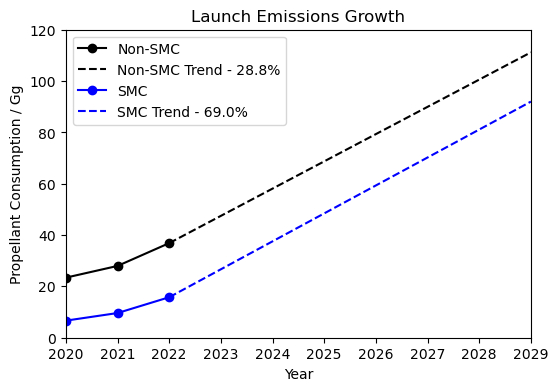

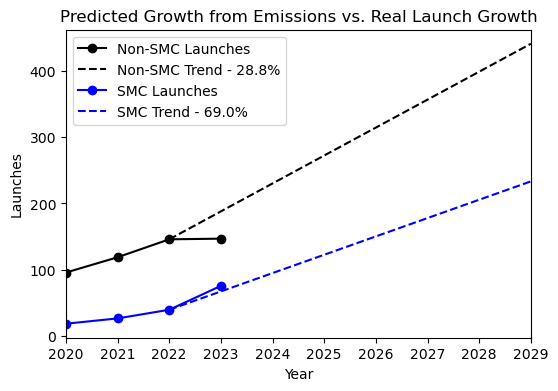

In [17]:
prop_growth = np.zeros((3,2))
years = [2020,2021,2022]
years_extended = np.arange(2022,2030)
for year_count,year in enumerate(years):
    for dataset in [1,2]:
        data = np.loadtxt(f"/home/ucfacb0/Emission_Inventory/Improved_Emission_Profile/Emission_Output/EmissionTotals_{year}_{dataset}.csv",skiprows=1,usecols=[2,3],delimiter=",")
        prop_growth[year_count,dataset-1] = data[12,0]
    
coef = np.polyfit(years,prop_growth[:,0],1)
print(coef)
growth_rate_nonsmc = np.round(coef[0]/prop_growth[0,0]*100,1)
coef = np.polyfit(years,prop_growth[:,1],1)
print(coef)
growth_rate_smc = np.round(coef[0]/prop_growth[0,1]*100)
print(prop_growth[0,:])

projected_non_smc, projected_smc = np.zeros(len(years_extended)), np.zeros(len(years_extended))
scalefactors_nonsmc, scalefactors_smc = [], []
for year_count,year in enumerate(years_extended):
    projected_non_smc[year_count] = prop_growth[2,0] / 100 * (100 + growth_rate_nonsmc * (year_count))
    scalefactors_nonsmc.append(np.round((100 + growth_rate_nonsmc * (year_count))/100,3))
    projected_smc[year_count] = prop_growth[2,1] / 100 * (100 + growth_rate_smc * (year_count))
    scalefactors_smc.append(np.round((100 + growth_rate_smc * (year_count))/100,3))
    print(projected_non_smc[year_count],projected_smc[year_count])
    
print(scalefactors_nonsmc)
print(scalefactors_smc)
        
fig, ax1 = plt.subplots(figsize=(6,4))
ax1.plot(years,prop_growth[:,0],'-o', label="Non-SMC",color="k")
ax1.plot(years_extended,projected_non_smc,'--', label=f"Non-SMC Trend - {growth_rate_nonsmc}%",color="k")
ax1.plot(years,prop_growth[:,1],'-o', label="SMC",color="b")
ax1.plot(years_extended,projected_smc,'--', label=f"SMC Trend - {growth_rate_smc}%",color="b")
ax1.set_xlabel("Year")
ax1.set_ylabel("Propellant Consumption / Gg")
ax1.set_xlim(2020,2029)
ax1.set_xticks(np.linspace(2020,2029,10))
ax1.set_ylim(0,120)
ax1.set_title(f"Launch Emissions Growth")
ax1.legend(loc='upper left');

non_smc_launches = [96,119,146,212+11-76]
smc_launches     = [19,27,40,76]
launch_years     = [2020,2021,2022,2023]
projected_non_smc, projected_smc = np.zeros(len(years_extended)), np.zeros(len(years_extended))
for year_count,year in enumerate(years_extended):
    projected_non_smc[year_count] = non_smc_launches[2] / 100 * (100 + growth_rate_nonsmc * (year_count))
    projected_smc[year_count] = smc_launches[2] / 100 * (100 + growth_rate_smc * (year_count))
    print(projected_non_smc[year_count],projected_smc[year_count])
    
fig, ax1 = plt.subplots(figsize=(6,4))
ax1.plot(launch_years,non_smc_launches,'-o', label="Non-SMC Launches",color="k")
ax1.plot(years_extended,projected_non_smc,'--', label=f"Non-SMC Trend - {growth_rate_nonsmc}%",color="k")
ax1.plot(launch_years,smc_launches,'-o', label="SMC Launches",color="b")
ax1.plot(years_extended,projected_smc,'--', label=f"SMC Trend - {growth_rate_smc}%",color="b")
ax1.set_xlabel("Year")
ax1.set_ylabel("Launches")
ax1.set_xlim(2020,2029)
ax1.set_xticks(np.linspace(2020,2029,10))
#ax1.set_ylim(0,120)
ax1.set_title(f"Predicted Growth from Emissions vs. Real Launch Growth")
ax1.legend(loc='upper left');


### Reentry Emissions




[ 3.5000e-01 -7.0646e+02]
[1.0, 1.217, 1.434, 1.651, 1.868, 2.085, 2.302, 2.519]
[1.0, 1.61, 2.22, 2.83, 3.44, 4.05, 4.66, 5.27]


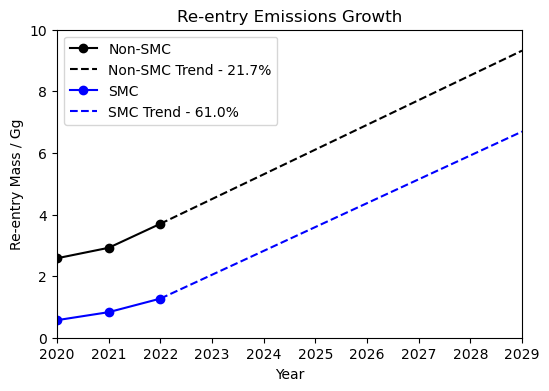

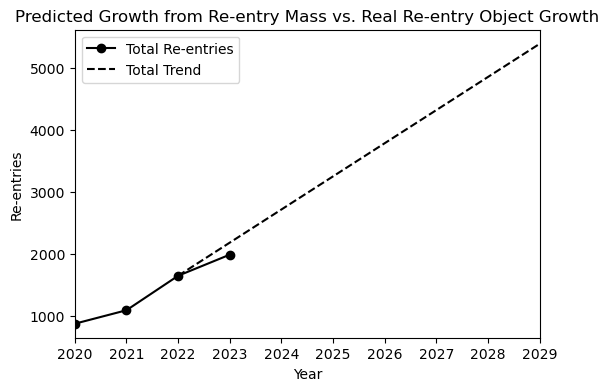

In [18]:

# Load reentry databases, check object mass.
# Same process as above, work out scale factors.

reentry_growth = np.zeros((3,2))
years = [2020,2021,2022]
years_extended = np.arange(2022,2030)
for year_count,year in enumerate(years):
    filename = f"./Databases/reentry_info_{year}_final_atlasbugfix.nc"
    ds = xr.open_dataset(filename, decode_times=False)
    df = pd.DataFrame(
    {   "Non Al Mass":      ds["Non_Al_Mass"].values,
        "Al Mass":          ds["Al_Mass"].values,
        "MCS":              ds["MCS"].values,
    }
    )
    df2 = df[(df["MCS"] == False)]
    df3 = df[(df["MCS"] == True)]
    reentry_growth[year_count,0] = np.round((np.sum(df2["Al Mass"].values)+np.sum(df2["Non Al Mass"].values))/1e6,2)
    reentry_growth[year_count,1] = np.round((np.sum(df3["Al Mass"].values)+np.sum(df3["Non Al Mass"].values))/1e6,2)
    print()
    
coef = np.polyfit(years,reentry_growth[:,0],1)
growth_rate_nonsmc = np.round(coef[0]/reentry_growth[0,0]*100,1)
coef = np.polyfit(years,reentry_growth[:,1],1)
print(coef)
growth_rate_smc = np.round(coef[0]/reentry_growth[0,1]*100)

projected_non_smc, projected_smc = np.zeros(len(years_extended)), np.zeros(len(years_extended))
scalefactors_nonsmc, scalefactors_smc = [], []
for year_count,year in enumerate(years_extended):
    projected_non_smc[year_count] = reentry_growth[2,0] / 100 * (100 + growth_rate_nonsmc * (year_count))
    scalefactors_nonsmc.append(np.round((100 + growth_rate_nonsmc * (year_count))/100,3))
    projected_smc[year_count] = reentry_growth[2,1] / 100 * (100 + growth_rate_smc * (year_count))
    scalefactors_smc.append(np.round((100 + growth_rate_smc * (year_count))/100,3))
    
print(scalefactors_nonsmc)
print(scalefactors_smc)
        
fig, ax1 = plt.subplots(figsize=(6,4))
ax1.plot(years,reentry_growth[:,0],'-o', label="Non-SMC",color="k")
ax1.plot(years_extended,projected_non_smc,'--', label=f"Non-SMC Trend - {growth_rate_nonsmc}%",color="k")
ax1.plot(years,reentry_growth[:,1],'-o', label="SMC",color="b")
ax1.plot(years_extended,projected_smc,'--', label=f"SMC Trend - {growth_rate_smc}%",color="b")
ax1.set_xlabel("Year")
ax1.set_ylabel("Re-entry Mass / Gg")
ax1.set_xlim(2020,2029)
ax1.set_xticks(np.linspace(2020,2029,10))
ax1.set_ylim(0,10)
ax1.set_title(f"Re-entry Emissions Growth")
ax1.legend(loc='upper left');

non_smc_reentries = [661,800,1203]
smc_reentries     = [217,295,447]
total_reentries = [661+217,800+295,1203+447,1990]
reentry_years     = [2020,2021,2022,2023]
projected_non_smc, projected_smc = np.zeros(len(years_extended)), np.zeros(len(years_extended))
for year_count,year in enumerate(years_extended):
    projected_non_smc[year_count] = non_smc_reentries[2] / 100 * (100 + growth_rate_nonsmc * (year_count))
    projected_smc[year_count] = smc_reentries[2] / 100 * (100 + growth_rate_smc * (year_count))
    
fig, ax1 = plt.subplots(figsize=(6,4))
ax1.plot(reentry_years,total_reentries,'-o', label="Total Re-entries",color="k")
ax1.plot(years_extended,projected_non_smc+projected_smc,'--', label=f"Total Trend",color="k")
ax1.set_xlabel("Year")
ax1.set_ylabel("Re-entries")
ax1.set_xlim(2020,2029)
ax1.set_xticks(np.linspace(2020,2029,10))
#ax1.set_ylim(0,120)
ax1.set_title(f"Predicted Growth from Re-entry Mass vs. Real Re-entry Object Growth")
ax1.legend(loc='upper left');

### Steady-State Scenario

In [19]:
# x SMC re-entries per year, x SMC payloads deployed per year to replenish.
# requires x additional launches per year.
# Look how other studies have done this (Jain, Schulz)

In [20]:
ds.close()